In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../../datasets/heart_final_cleaned.csv")
df = df.dropna().reset_index(drop=True)

X = df.drop("target", axis=1).values.astype(float)
y = df["target"].values.astype(int)

print("Dataset Shape:", df.shape)
print(df["target"].value_counts())

Dataset Shape: (302, 14)
target
1    164
0    138
Name: count, dtype: int64


In [3]:
def split_data(X, y, test_size=0.2, seed=42):

    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []

    for cls in np.unique(y):
        idx = np.where(y == cls)[0]
        rng.shuffle(idx)

        split = int(len(idx) * (1 - test_size))
        train_idx.extend(idx[:split])
        test_idx.extend(idx[split:])

    return (X[train_idx], X[test_idx],
            y[train_idx], y[test_idx])


X_temp, X_test, y_temp, y_test = split_data(X, y)

X_train, X_val, y_train, y_val = split_data(
    X_temp, y_temp, test_size=0.25, seed=21
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (180, 13)
Validation: (61, 13)
Testing: (61, 13)


In [4]:
def sigmoid(x):
    x = np.clip(x, -15, 15)
    return 1 / (1 + np.exp(-x))


def calculate_gradient_hessian(y, predictions):

    p = sigmoid(predictions)

    gradient = p - y
    hessian = p * (1 - p)

    return gradient, hessian

In [5]:
def calculate_gain(GL, HL, GR, HR, G, H, reg_lambda):

    left_score = GL ** 2 / (HL + reg_lambda)
    right_score = GR ** 2 / (HR + reg_lambda)
    parent_score = G ** 2 / (H + reg_lambda)

    return 0.5 * (left_score + right_score - parent_score)

In [6]:
def build_tree(X, grad, hess, depth, max_depth, reg_lambda):

    G, H = np.sum(grad), np.sum(hess)
    leaf_value = -G / (H + reg_lambda)

    if depth >= max_depth or len(X) < 2:
        return leaf_value

    best_gain = 0
    best_feature = None
    best_threshold = None

    for feature in range(X.shape[1]):

        values = np.unique(X[:, feature])

        for threshold in (values[:-1] + values[1:]) / 2:

            left = X[:, feature] <= threshold
            right = ~left

            if not left.any() or not right.any():
                continue

            GL, HL = np.sum(grad[left]), np.sum(hess[left])
            GR, HR = np.sum(grad[right]), np.sum(hess[right])

            gain = calculate_gain(
                GL, HL, GR, HR, G, H, reg_lambda
            )

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_threshold = threshold

    if best_feature is None:
        return leaf_value

    left = X[:, best_feature] <= best_threshold
    right = ~left

    return {
        "feature": best_feature,
        "threshold": best_threshold,
        "left": build_tree(
            X[left], grad[left], hess[left],
            depth + 1, max_depth, reg_lambda
        ),
        "right": build_tree(
            X[right], grad[right], hess[right],
            depth + 1, max_depth, reg_lambda
        )
    }

In [7]:
def predict_tree(tree, row):

    while isinstance(tree, dict):

        if row[tree["feature"]] <= tree["threshold"]:
            tree = tree["left"]
        else:
            tree = tree["right"]

    return tree

In [8]:
def train_xgboost(X, y, n_estimators, learning_rate,
                  max_depth, reg_lambda):

    base_p = np.clip(np.mean(y), 1e-5, 1 - 1e-5)
    base_score = np.log(base_p / (1 - base_p))

    predictions = np.full(len(y), base_score)
    trees = []

    for _ in range(n_estimators):

        grad, hess = calculate_gradient_hessian(y, predictions)

        tree = build_tree(
            X, grad, hess, 0, max_depth, reg_lambda
        )

        trees.append(tree)

        updates = np.array([
            predict_tree(tree, row) for row in X
        ])

        predictions += learning_rate * updates

    return base_score, trees

In [9]:
def predict_xgboost(X, base_score, trees, learning_rate):

    predictions = np.full(len(X), base_score)

    for tree in trees:

        updates = np.array([
            predict_tree(tree, row) for row in X
        ])

        predictions += learning_rate * updates

    return (sigmoid(predictions) >= 0.5).astype(int)


def accuracy_score_manual(y_true, y_pred):

    correct = sum(y_true == y_pred)

    return correct / len(y_true) * 100

In [10]:
parameter_space = {
    "n_estimators": [10, 20, 30],
    "learning_rate": [0.05, 0.1, 0.2],
    "max_depth": [1, 2, 3],
    "reg_lambda": [1, 5, 10]
}

print("Total possible combinations:",
      np.prod([len(v) for v in parameter_space.values()]))

Total possible combinations: 81


In [11]:
rng = np.random.default_rng(42)

n_iterations = 8
results = []
best_accuracy = -1
best_params = None

for iteration in range(n_iterations):

    params = {
        key: rng.choice(values).item()
        for key, values in parameter_space.items()
    }

    base_score, trees = train_xgboost(
        X_train, y_train, **params
    )

    predictions = predict_xgboost(
        X_val, base_score, trees, params["learning_rate"]
    )

    accuracy = accuracy_score_manual(y_val, predictions)

    results.append({
        **params,
        "Validation Accuracy": accuracy
    })

    print(f"Iteration {iteration + 1}: "
          f"Accuracy = {accuracy:.2f}% | Parameters = {params}")

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_params = params.copy()

print("\nBest Parameters:", best_params)
print("Best Validation Accuracy:", round(best_accuracy, 2), "%")

Iteration 1: Accuracy = 80.33% | Parameters = {'n_estimators': 10, 'learning_rate': 0.2, 'max_depth': 2, 'reg_lambda': 5}
Iteration 2: Accuracy = 80.33% | Parameters = {'n_estimators': 20, 'learning_rate': 0.2, 'max_depth': 1, 'reg_lambda': 10}
Iteration 3: Accuracy = 73.77% | Parameters = {'n_estimators': 10, 'learning_rate': 0.05, 'max_depth': 2, 'reg_lambda': 10}
Iteration 4: Accuracy = 81.97% | Parameters = {'n_estimators': 30, 'learning_rate': 0.2, 'max_depth': 3, 'reg_lambda': 10}
Iteration 5: Accuracy = 81.97% | Parameters = {'n_estimators': 20, 'learning_rate': 0.05, 'max_depth': 3, 'reg_lambda': 5}
Iteration 6: Accuracy = 81.97% | Parameters = {'n_estimators': 20, 'learning_rate': 0.1, 'max_depth': 1, 'reg_lambda': 10}
Iteration 7: Accuracy = 80.33% | Parameters = {'n_estimators': 30, 'learning_rate': 0.1, 'max_depth': 2, 'reg_lambda': 10}
Iteration 8: Accuracy = 80.33% | Parameters = {'n_estimators': 20, 'learning_rate': 0.1, 'max_depth': 2, 'reg_lambda': 1}

Best Parameters:

In [12]:
results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "Validation Accuracy", ascending=False
    )
)

,n_estimators,learning_rate,max_depth,reg_lambda,Validation Accuracy
3,30,0.20,3,10,81.967213
4,20,0.05,3,5,81.967213
5,20,0.10,1,10,81.967213
0,10,0.20,2,5,80.327869
6,30,0.10,2,10,80.327869
1,20,0.20,1,10,80.327869
7,20,0.10,2,1,80.327869
2,10,0.05,2,10,73.770492


In [13]:
X_final_train = np.vstack((X_train, X_val))
y_final_train = np.concatenate((y_train, y_val))

final_base_score, final_trees = train_xgboost(
    X_final_train,
    y_final_train,
    **best_params
)

final_predictions = predict_xgboost(
    X_test,
    final_base_score,
    final_trees,
    best_params["learning_rate"]
)

test_accuracy = accuracy_score_manual(
    y_test, final_predictions
)

print("Best Parameters:", best_params)
print("Final Test Accuracy:", round(test_accuracy, 2), "%")

Best Parameters: {'n_estimators': 30, 'learning_rate': 0.2, 'max_depth': 3, 'reg_lambda': 10}
Final Test Accuracy: 80.33 %


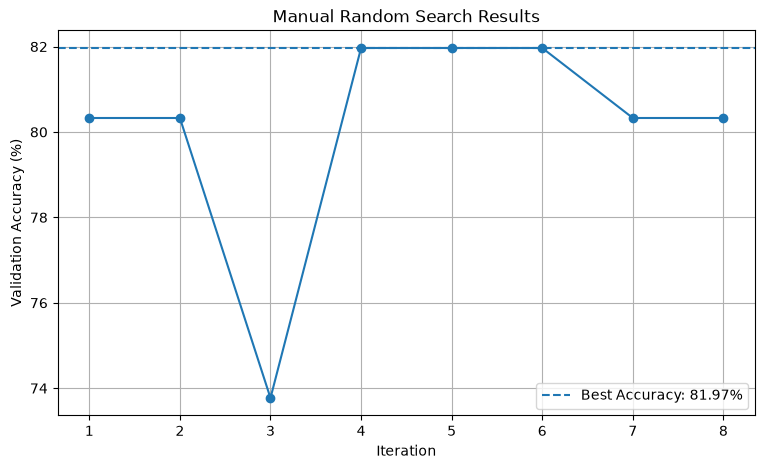

In [14]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, n_iterations + 1),
    results_df["Validation Accuracy"],
    marker="o"
)

plt.axhline(
    best_accuracy,
    linestyle="--",
    label=f"Best Accuracy: {best_accuracy:.2f}%"
)

plt.title("Manual Random Search Results")
plt.xlabel("Iteration")
plt.ylabel("Validation Accuracy (%)")
plt.xticks(range(1, n_iterations + 1))
plt.legend()
plt.grid()
plt.show()

## Conclusion

In this task, manual Random Search was implemented to tune the
hyperparameters of an XGBoost-style Gradient Boosting model.

Different combinations of the number of estimators, learning rate,
maximum tree depth, and regularization strength were randomly selected.

Each configuration was evaluated using validation accuracy, and the
best configuration was selected.

Finally, the model was retrained using the combined training and
validation datasets and evaluated on the independent test dataset.

This approach demonstrates hyperparameter optimization without
using RandomizedSearchCV.